# <u>**TecnoForms - Clasificación de Dígitos Manuscritos**</u>

**Comparación:** CNN (*Deep Learning*) vs KNN vs SVM (*Machine Learning clásico*)

Este script:
1. Descarga el dataset MNIST (70,000 imágenes de dígitos 0-9)
2. Preprocesa las imágenes (normalización, escala de grises ya viene así)
3. Entrena una CNN (*Red Neuronal Convolucional*)
4. Entrena un KNN (*K-Nearest Neighbors*)y un SVM (*Support Vector Machine*) para comparar
5. Evalúa los 3 modelos con métricas (precisión, recall, F1, matriz de confusión)
6. Muestra ejemplos visuales de predicciones vs etiquetas reales



`Configurar el entorno para usar GPU T4`

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, ConfusionMatrixDisplay,
                              classification_report)
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping


## **➤ &nbsp;<u>PASO 1: Cargar el Dataset MNIST**</u>

In [ ]:
# Ya viene dividido en entrenamiento (60,000 imágenes) y test (10,000 imágenes)
# Cada imagen es de 28x28 píxeles, en escala de grises (valores 0-255)
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print(f"Imágenes de entrenamiento: {X_train.shape}")  # (60000, 28, 28)
print(f"Imágenes de test: {X_test.shape}")             # (10000, 28, 28)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Imágenes de entrenamiento: (60000, 28, 28)
Imágenes de test: (10000, 28, 28)


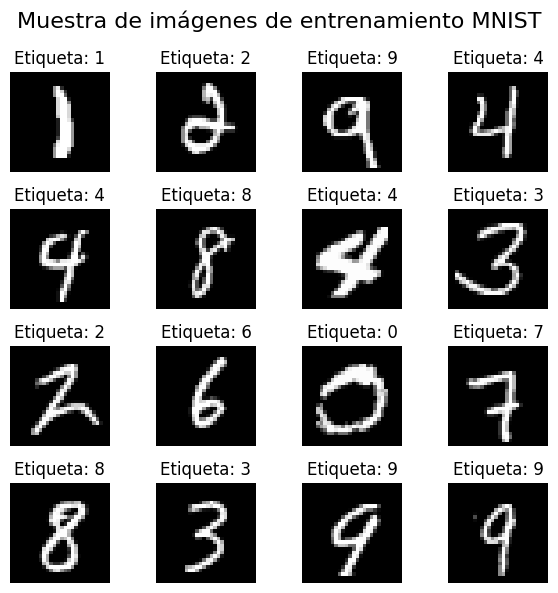

In [ ]:
fig, axes = plt.subplots(4, 4, figsize=(6,6))

for i, ax in enumerate(axes.flat):
    index = np.random.randint(len(X_train))
    ax.imshow(X_train[index], cmap="gray")
    ax.set_title(f"Etiqueta: {y_train[index]}")
    ax.axis("off")

plt.suptitle("Muestra de imágenes de entrenamiento MNIST", fontsize=16)
plt.tight_layout()
plt.show()

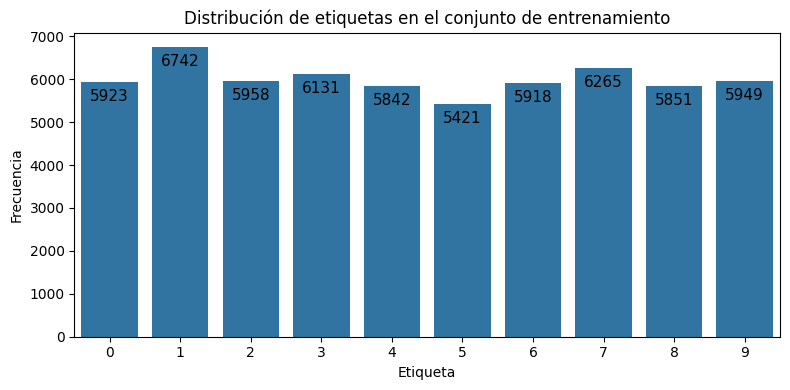

In [ ]:
plt.figure(figsize=(8,4))
ax = sns.countplot(x=y_train)
plt.title("Distribución de etiquetas en el conjunto de entrenamiento")
plt.xlabel("Etiqueta")
plt.ylabel("Frecuencia")
plt.savefig("distribucion_etiquetas.png")
plt.tight_layout()

for bar in ax.patches:
    ax.annotate(f'{int(bar.get_height())}',(bar.get_x()+bar.get_width()/2., bar.get_height()-500),
                ha='center', va='center', fontsize=11, color='black', xytext=(0, 5),
                textcoords='offset points')

plt.show()

## **➤ &nbsp;<u>PASO 2: Preprocesamiento**</u>

In [ ]:
# Normalización: pasamos los valores de píxel de 0-255 a 0-1
# (esto ayuda a que la red entrene más rápido y estable)
X_train_norm = X_train.astype("float32") / 255.0
X_test_norm = X_test.astype("float32") / 255.0


In [ ]:
# --- Versión para la CNN (necesita forma: alto x ancho x canales) ---
X_train_cnn = X_train_norm.reshape(-1, 28, 28, 1)
X_test_cnn = X_test_norm.reshape(-1, 28, 28, 1)


In [ ]:
# Las etiquetas (0-9) se convierten a "one-hot encoding" para la CNN
# Ejemplo: el número 3 se convierte en [0,0,0,1,0,0,0,0,0,0]
y_train_cnn = to_categorical(y_train, 10)
y_test_cnn = to_categorical(y_test, 10)


In [ ]:
# --- Versión para KNN y SVM (necesitan los datos "aplanados" en una fila) ---
# Convertimos cada imagen 28x28 en un solo vector de 784 números
X_train_flat = X_train_norm.reshape(-1, 28 * 28)
X_test_flat = X_test_norm.reshape(-1, 28 * 28)


In [ ]:
# KNN y SVM son mucho más lentos que la CNN con muchos datos,
# así que usamos una muestra reducida para que no tarde horas.
n_muestra = 10000
X_train_flat_sample = X_train_flat[:n_muestra]
y_train_sample = y_train[:n_muestra]


## **➤ &nbsp;<u>Definir y entrenar la CNN**</u>

In [ ]:
modelo_cnn = Sequential([
    # Primera capa convolucional: 32 filtros, detectan patrones simples (bordes)
    Conv2D(32, kernel_size=(3, 3), activation="relu", input_shape=(28, 28, 1)),
    MaxPooling2D(pool_size=(2, 2)),  # Reduce el tamaño, se queda con lo importante

    # Segunda capa convolucional: 64 filtros, detectan patrones más complejos
    Conv2D(64, kernel_size=(3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Flatten(),  # Aplana todo para pasarlo a las capas densas

    Dense(128, activation="relu"),  # Capa densa: combina lo aprendido
    Dropout(0.3),  # Apaga el 30% de neuronas al azar para evitar sobreajuste

    Dense(10, activation="softmax")  # Capa de salida: 10 neuronas (una por dígito)
])

modelo_cnn.compile(
    optimizer="adam",                  # Estrategia de optimización
    loss="categorical_crossentropy",   # Función de pérdida (mide el error)
    metrics=["accuracy"]
)

modelo_cnn.summary()  # Muestra la arquitectura completa (para tu informe)

# Early stopping: detiene el entrenamiento si deja de mejorar
early_stop = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

print("\nEntrenando la CNN...")
historial = modelo_cnn.fit(
    X_train_cnn, y_train_cnn,
    epochs=15,              # número de veces que revisa todo el dataset
    batch_size=128,         # tamaño de los "lotes" de imágenes
    validation_split=0.1,   # separa 10% del train para validar durante el entrenamiento
    callbacks=[early_stop],
    verbose=1
)



/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)


Entrenando la CNN...
Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.9240 - loss: 0.2539 - val_accuracy: 0.9838 - val_loss: 0.0604
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9774 - loss: 0.0744 - val_accuracy: 0.9885 - val_loss: 0.0441
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9854 - loss: 0.0509 - val_accuracy: 0.9887 - val_loss: 0.0361
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9875 - loss: 0.0400 - val_accuracy: 0.9905 - val_loss: 0.0350
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9896 - loss: 0.0336 - val_accuracy: 0.9922 - val_loss: 0.0292
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9910 - loss: 0.0283 - val_accuracy: 0.9890 - val_loss: 0.0367
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9922 - loss: 0.0230 - val_accuracy: 0.9920 - val_loss: 0.0285
Epoch 8/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9931 - loss: 0

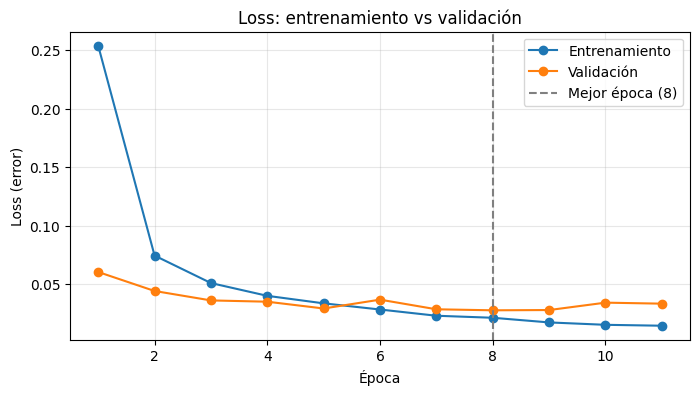

In [ ]:
loss = historial.history["loss"]
val_loss = historial.history["val_loss"]
epocas = range(1, len(loss) + 1)
mejor = val_loss.index(min(val_loss)) + 1  # época con el menor val_loss

plt.figure(figsize=(8, 4))
plt.plot(epocas, loss, marker="o", label="Entrenamiento")
plt.plot(epocas, val_loss, marker="o", label="Validación")
plt.axvline(mejor, linestyle="--", color="gray", label=f"Mejor época ({mejor})")
plt.xlabel("Época")
plt.ylabel("Loss (error)")
plt.title("Loss: entrenamiento vs validación")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("curva_loss.png", dpi=150)
plt.show()

In [ ]:
# Guardamos el modelo ya entrenado en un archivo .h5, para poder
# reutilizarlo después (por ejemplo, para predecir con imágenes reales)
# sin tener que reentrenar cada vez.
modelo_cnn.save("cnn_digitos.h5")
print("Modelo guardado como cnn_digitos.h5")

Modelo guardado como cnn_digitos.h5


## **➤ &nbsp;<u>PASO 4: Definir y entrenar el KNN**</u>

![Imagen de KNN](https://media.licdn.com/dms/image/v2/C5612AQFIchf9cV1Viw/article-cover_image-shrink_600_2000/article-cover_image-shrink_600_2000/0/1591802768087?e=2147483647&v=beta&t=r_WeVpsbgP21eU3UPHziME7B_OaeV_WLIPkX6RmOGPM)

In [ ]:
print("\nEntrenando KNN...")
modelo_knn = KNeighborsClassifier(n_neighbors=5)
modelo_knn.fit(X_train_flat_sample, y_train_sample)




Entrenando KNN...


KNeighborsClassifier()

## **➤ &nbsp;<u>PASO 5. Definir y entrenar el SVM**</u>

![Imagen de SVM](https://substackcdn.com/image/fetch/$s_!sfcn!,f_auto,q_auto:good,fl_progressive:steep/https%3A%2F%2Fsubstack-post-media.s3.amazonaws.com%2Fpublic%2Fimages%2Fee1fcf7b-efbf-41de-b9e7-049d1e66b6e3_552x298.webp)

In [ ]:
print("\nEntrenando SVM...")
modelo_svm = SVC(kernel="rbf", gamma="scale")
modelo_svm.fit(X_train_flat_sample, y_train_sample)



Entrenando SVM...


SVC()

## **➤ &nbsp;<u>PASO 6: Evaluación de los 3 modelos**</u>

In [ ]:
def evaluar_modelo(nombre, y_real, y_pred):
    print(f"\n===== Resultados: {nombre} =====")
    print(f"Accuracy (exactitud): {accuracy_score(y_real, y_pred):.4f}")
    print(f"Precision: {precision_score(y_real, y_pred, average='macro'):.4f}")
    print(f"Recall: {recall_score(y_real, y_pred, average='macro'):.4f}")
    print(f"F1-score: {f1_score(y_real, y_pred, average='macro'):.4f}")
    print("\nReporte completo:")
    print(classification_report(y_real, y_pred))

    # Matriz de confusión
    cm = confusion_matrix(y_real, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(cmap="Blues")
    plt.title(f"Matriz de confusión - {nombre}")
    plt.savefig(f"matriz_confusion_{nombre}.png")
    plt.show()

### Evaluar CNN

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step

===== Resultados: CNN =====
Accuracy (exactitud): 0.9935
Precision: 0.9935
Recall: 0.9934
F1-score: 0.9934

Reporte completo:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       980
           1       1.00      1.00      1.00      1135
           2       0.99      1.00      0.99      1032
           3       0.99      1.00      0.99      1010
           4       0.99      1.00      1.00       982
           5       0.99      0.99      0.99       892
           6       1.00      0.99      0.99       958
           7       0.99      0.99      0.99      1028
           8       1.00      0.99      0.99       974
           9       0.99      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



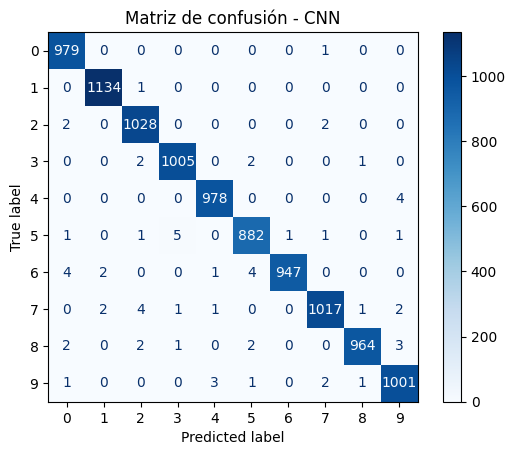

In [ ]:
y_pred_cnn_probs = modelo_cnn.predict(X_test_cnn)
y_pred_cnn = np.argmax(y_pred_cnn_probs, axis=1)  # convierte probabilidades en el dígito predicho
evaluar_modelo("CNN", y_test, y_pred_cnn)

### Evaluar KNN


===== Resultados: KNN =====
Accuracy (exactitud): 0.9442
Precision: 0.9459
Recall: 0.9436
F1-score: 0.9441

Reporte completo:
              precision    recall  f1-score   support

           0       0.94      0.99      0.97       980
           1       0.91      0.99      0.95      1135
           2       0.98      0.91      0.94      1032
           3       0.93      0.95      0.94      1010
           4       0.96      0.93      0.95       982
           5       0.96      0.93      0.94       892
           6       0.95      0.98      0.97       958
           7       0.93      0.93      0.93      1028
           8       0.97      0.88      0.93       974
           9       0.92      0.93      0.93      1009

    accuracy                           0.94     10000
   macro avg       0.95      0.94      0.94     10000
weighted avg       0.95      0.94      0.94     10000



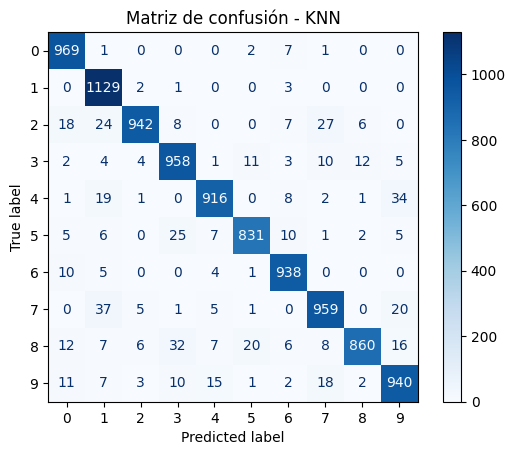

In [ ]:
y_pred_knn = modelo_knn.predict(X_test_flat)
evaluar_modelo("KNN", y_test, y_pred_knn)

### Evaluar SVM


===== Resultados: SVM =====
Accuracy (exactitud): 0.9594
Precision: 0.9594
Recall: 0.9590
F1-score: 0.9591

Reporte completo:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       980
           1       0.98      0.99      0.98      1135
           2       0.95      0.96      0.95      1032
           3       0.95      0.95      0.95      1010
           4       0.95      0.96      0.95       982
           5       0.97      0.94      0.96       892
           6       0.97      0.98      0.97       958
           7       0.96      0.94      0.95      1028
           8       0.96      0.95      0.95       974
           9       0.96      0.92      0.94      1009

    accuracy                           0.96     10000
   macro avg       0.96      0.96      0.96     10000
weighted avg       0.96      0.96      0.96     10000



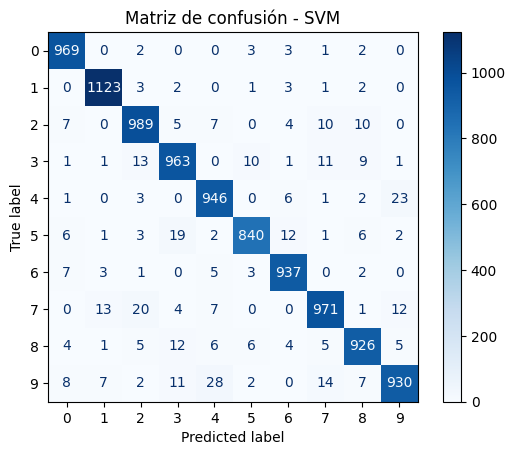

In [ ]:
y_pred_svm = modelo_svm.predict(X_test_flat)
evaluar_modelo("SVM", y_test, y_pred_svm)

## **➤ &nbsp;<u>PASO 7: Resultados Visuales - Predicciones vs Etiquetas Reales**</u>

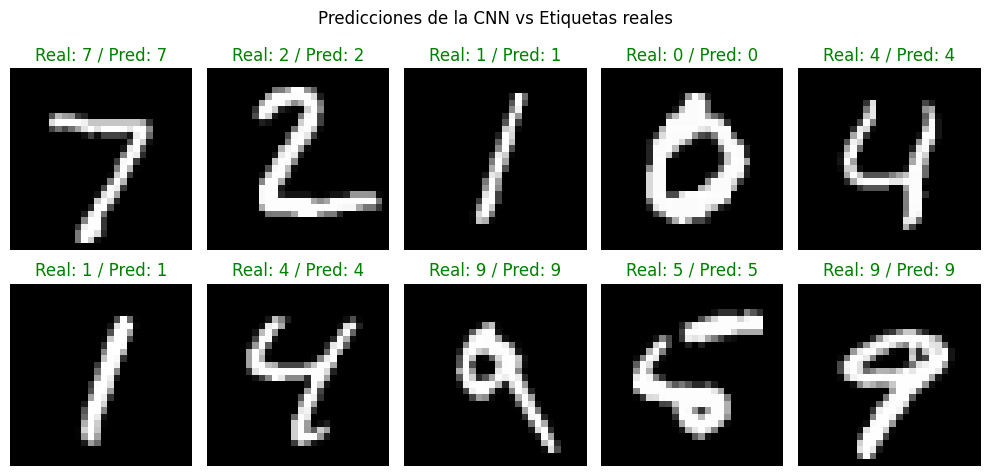

In [ ]:
plt.figure(figsize=(10, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i], cmap="gray")
    color = "green" if y_pred_cnn[i] == y_test[i] else "red"
    plt.title(f"Real: {y_test[i]} / Pred: {y_pred_cnn[i]}", color=color)
    plt.axis("off")
plt.suptitle("Predicciones de la CNN vs Etiquetas reales")
plt.tight_layout()
plt.savefig("predicciones_vs_reales.png")
plt.show()


## **➤ &nbsp;<u>PASO 8: Comparación Final entre los 3 modelos**</u>


===== COMPARACIÓN FINAL (Accuracy) =====
CNN: 0.9935
KNN: 0.9442
SVM: 0.9594


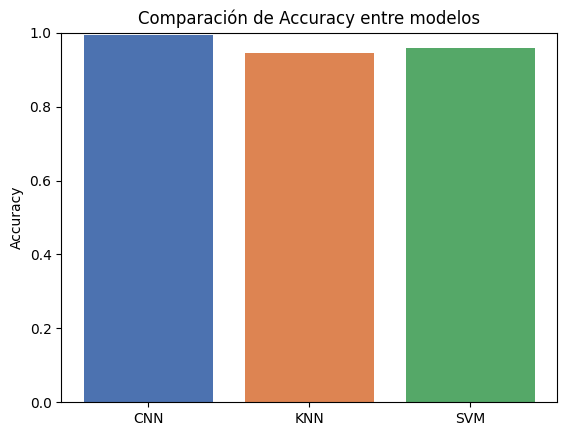

In [ ]:
resultados = {
    "CNN": accuracy_score(y_test, y_pred_cnn),
    "KNN": accuracy_score(y_test, y_pred_knn),
    "SVM": accuracy_score(y_test, y_pred_svm),
}

print("\n===== COMPARACIÓN FINAL (Accuracy) =====")
for modelo, acc in resultados.items():
    print(f"{modelo}: {acc:.4f}")

plt.figure()
plt.bar(resultados.keys(), resultados.values(), color=["#4C72B0", "#DD8452", "#55A868"])
plt.title("Comparación de Accuracy entre modelos")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.savefig("comparacion_modelos.png")
plt.show()

## **➤ &nbsp;<u>PASO 9: Prueba del Modelo con una imagen**</u>

In [ ]:
"""
Este script toma una foto tuya (dígito escrito a mano, escaneado o fotografiado)
y la transforma para que se parezca a como el modelo aprendió a ver los dígitos en MNIST,
antes de predecir.
"""
import numpy as np
import cv2  # OpenCV: para leer y transformar la imagen
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model

In [ ]:
modelo = load_model("cnn_digitos.h5")
modelo

<Sequential name=sequential, built=True>

In [ ]:
def preprocesar_imagen_real(ruta_imagen, mostrar_pasos=True):
    """
    Convierte una foto real de un dígito al formato que espera el modelo:
    28x28 píxeles, escala de grises, dígito BLANCO sobre fondo NEGRO,
    normalizado y centrado.
    """
    # 1. Leer la imagen en escala de grises directamente
    img = cv2.imread(ruta_imagen, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"No se pudo leer la imagen en: {ruta_imagen}")

    # 2. Detectar si es "tinta oscura sobre papel claro" (lo normal en fotos)
    #    y en ese caso invertir los colores, porque MNIST es al revés
    #    (dígito claro sobre fondo oscuro).
    promedio_fondo = np.mean(img)
    if promedio_fondo > 127:  # si el promedio es claro, el fondo es blanco
        img = cv2.bitwise_not(img)  # invierte: ahora el dígito queda blanco

    # 3. Binarizar (blanco y negro puro) para quitar ruido, sombras, manchas
    _, img_binaria = cv2.threshold(img, 50, 255, cv2.THRESH_BINARY)

    # 4. Encontrar el contorno del dígito para recortarlo (quitar espacio vacío)
    contornos, _ = cv2.findContours(img_binaria, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if contornos:
        # Toma el contorno más grande (asumimos que es el dígito)
        contorno_mayor = max(contornos, key=cv2.contourArea)
        x, y, w, h = cv2.boundingRect(contorno_mayor)
        img_recortada = img_binaria[y:y + h, x:x + w]
    else:
        img_recortada = img_binaria  # si no encuentra nada, usa la imagen completa

    # 5. Agregar un margen (padding) alrededor del dígito, para que no
    #    quede pegado a los bordes (así se ve MNIST también)
    margen = int(max(img_recortada.shape) * 0.2)
    img_con_margen = cv2.copyMakeBorder(
        img_recortada, margen, margen, margen, margen,
        cv2.BORDER_CONSTANT, value=0
    )

    # 6. Redimensionar a 28x28 (el tamaño que espera el modelo)
    img_28x28 = cv2.resize(img_con_margen, (28, 28), interpolation=cv2.INTER_AREA)

    # 7. Normalizar los valores de píxel (0-255 -> 0-1), igual que en el entrenamiento
    img_normalizada = img_28x28.astype("float32") / 255.0

    if mostrar_pasos:
        fig, ejes = plt.subplots(1, 3, figsize=(9, 3))
        ejes[0].imshow(cv2.imread(ruta_imagen), cmap="gray")
        ejes[0].set_title("Imagen original")
        ejes[1].imshow(img_binaria, cmap="gray")
        ejes[1].set_title("Binarizada")
        ejes[2].imshow(img_28x28, cmap="gray")
        ejes[2].set_title("Lista para el modelo (28x28)")
        for eje in ejes:
            eje.axis("off")
        plt.tight_layout()
        plt.show()

    # 8. Darle la forma que espera la CNN: (1, 28, 28, 1)
    return img_normalizada.reshape(1, 28, 28, 1)

In [ ]:
def predecir_digito(ruta_imagen):
    imagen_lista = preprocesar_imagen_real(ruta_imagen)
    probabilidades = modelo.predict(imagen_lista)[0]
    digito_predicho = np.argmax(probabilidades)
    confianza = probabilidades[digito_predicho] * 100

    print(f"\nDígito predicho: {digito_predicho}")
    print(f"Confianza: {confianza:.2f}%")
    print("\nProbabilidades por dígito:")
    for i, prob in enumerate(probabilidades):
        barra = "█" * int(prob * 30)
        print(f"  {i}: {prob*100:5.2f}% {barra}")

    return digito_predicho, confianza


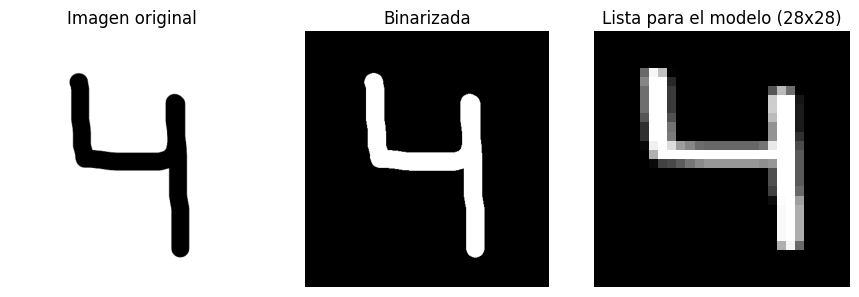

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 681ms/step

Dígito predicho: 4
Confianza: 100.00%

Probabilidades por dígito:
  0:  0.00% 
  1:  0.00% 
  2:  0.00% 
  3:  0.00% 
  4: 100.00% █████████████████████████████
  5:  0.00% 
  6:  0.00% 
  7:  0.00% 
  8:  0.00% 
  9:  0.00% 


In [ ]:
# ---------------------------------------------------------------------
# USO: cambia esta ruta por la de tu imagen
# ---------------------------------------------------------------------
if __name__ == "__main__":
    ruta = "/content/image.png"  # <-- reemplaza con el nombre de tu imagen
    predecir_digito(ruta)

## **➤ &nbsp;<u>PASO 10: Obtener los archivos CSV para crear los Dashboards en Power BI**</u>

In [ ]:
import pandas as pd
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)


predicciones = {"CNN": y_pred_cnn, "KNN": y_pred_knn, "SVM": y_pred_svm}

# 1) Métricas globales por modelo
filas = []
for nombre, y_pred in predicciones.items():
    p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="macro")
    filas.append({"modelo": nombre, "accuracy": accuracy_score(y_test, y_pred),
                  "precision": p, "recall": r, "f1": f1})
pd.DataFrame(filas).to_csv("metricas_modelos.csv", index=False)

# 2) Métricas por dígito
filas = []
for nombre, y_pred in predicciones.items():
    rep = classification_report(y_test, y_pred, output_dict=True)
    for d in range(10):
        m = rep[str(d)]
        filas.append({"modelo": nombre, "digito": d, "precision": m["precision"],
                      "recall": m["recall"], "f1": m["f1-score"], "soporte": int(m["support"])})
pd.DataFrame(filas).to_csv("metricas_por_digito.csv", index=False)

# 3) Matriz de confusión en formato largo (una fila por celda)
filas = []
for nombre, y_pred in predicciones.items():
    cm = confusion_matrix(y_test, y_pred)
    for real in range(10):
        for pred in range(10):
            filas.append({"modelo": nombre, "real": real, "predicho": pred,
                          "cantidad": int(cm[real, pred])})
pd.DataFrame(filas).to_csv("matriz_confusion.csv", index=False)

# 4) Historial de entrenamiento de la CNN
h = pd.DataFrame(historial.history)
h.insert(0, "epoca", range(1, len(h) + 1))
h.to_csv("historial_entrenamiento.csv", index=False)

# 5) Predicción de cada imagen del test
pd.DataFrame({
    "indice": range(len(y_test)),
    "real": y_test,
    "pred_cnn": y_pred_cnn,
    "confianza_cnn": y_pred_cnn_probs.max(axis=1),
    "pred_knn": y_pred_knn,
    "pred_svm": y_pred_svm,
}).to_csv("predicciones_test.csv", index=False)

# Empaquetar y descargar todo
!zip -q datos_powerbi.zip metricas_modelos.csv metricas_por_digito.csv matriz_confusion.csv historial_entrenamiento.csv predicciones_test.csv
from google.colab import files
files.download("datos_powerbi.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## **➤ &nbsp;<u>Conclusiones**</u>

* La CNN fue el mejor modelo. Alcanzó 99.00% de exactitud en el conjunto de test, superando al SVM (95.13%) por 3.87 puntos y al KNN (93.25%) por 5.75 puntos. En la práctica, la CNN falla alrededor de 1 de cada 100 dígitos, el SVM casi 5 y el KNN casi 7. En un formulario de pagos o inscripciones, esa diferencia significa cientos de errores más al procesar miles de dígitos.


* La ventaja viene de cómo cada modelo “ve” la imagen. KNN y SVM reciben la imagen aplanada en 784 números, sin noción de qué píxeles están cerca. La CNN, con sus capas convolucionales, detecta trazos y curvas y los combina en formas, lo que la hace más robusta a variaciones en la escritura.

* El entrenamiento fue estable. Las curvas de pérdida de entrenamiento y validación bajaron juntas durante las primeras épocas. A partir de la época 5 la validación se estabilizó (~0.03) mientras el entrenamiento seguía bajando, indicio leve de sobreajuste. El mejor resultado se obtuvo en la época 7, y el early stopping detuvo el entrenamiento en la 10 y restauró esos pesos, evitando entrenar de más.

* El preprocesamiento es tan importante como el modelo. Un dígito real no se parece a uno de MNIST (tinta oscura sobre papel claro, ruido, distinto tamaño). Convertir a escala de grises, detectar el fondo, binarizar con umbral automático (Otsu), recortar, centrar y redimensionar a 28×28 es lo que permite usar un modelo entrenado en MNIST con imágenes de formularios.

* La solución es viable como producto. El modelo se sirve con una API (FastAPI) y se consume desde una interfaz web (Astro) donde el usuario dibuja un dígito y recibe la predicción con su nivel de confianza, lo que demuestra que el sistema puede integrarse en un flujo real de TecnoForms.